In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving Zomato data .csv to Zomato data  (2).csv


In [7]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 148
Columns: 7


In [8]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 148
Number of columns: 7


In [11]:
print("Columns in the dataset:")

for column in df.columns:
    print(column)

Columns in the dataset:
name
online_order
book_table
rate
votes
approx_cost(for two people)
listed_in(type)


In [12]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64


In [13]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [14]:
df = df.drop_duplicates()

print("Duplicates removed.")
print("New shape:", df.shape)

Duplicates removed.
New shape: (148, 7)


In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,148,145,San Churro Cafe,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_order,148,2,No,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
book_table,148,2,No,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,148,20,3.8/5,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
votes,148.0,NaN,NaN,NaN,264.810811,653.676951,0.0,6.75,43.5,221.75,4884.0
approx_cost(for two people),148.0,NaN,NaN,NaN,418.243243,223.085098,100.0,200.0,400.0,600.0,950.0
listed_in(type),148,4,Dining,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df['rate'] = df['rate'].astype(str)

df['rate'] = df['rate'].replace('NEW', np.nan)
df['rate'] = df['rate'].replace('-', np.nan)

df['rate'] = df['rate'].str.split('/').str[0]

df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

print(df['rate'].head())

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: rate, dtype: float64


In [17]:
cost_column = 'approx_cost(for two people)'

if cost_column in df.columns:
    df[cost_column] = df[cost_column].astype(str)
    df[cost_column] = df[cost_column].str.replace(',', '', regex=False)
    df[cost_column] = pd.to_numeric(df[cost_column], errors='coerce')

print(df[cost_column].head())

0    800
1    800
2    800
3    300
4    600
Name: approx_cost(for two people), dtype: int64


In [18]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [19]:
restaurant_type_counts = df['listed_in(type)'].value_counts()

print(restaurant_type_counts)

listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64


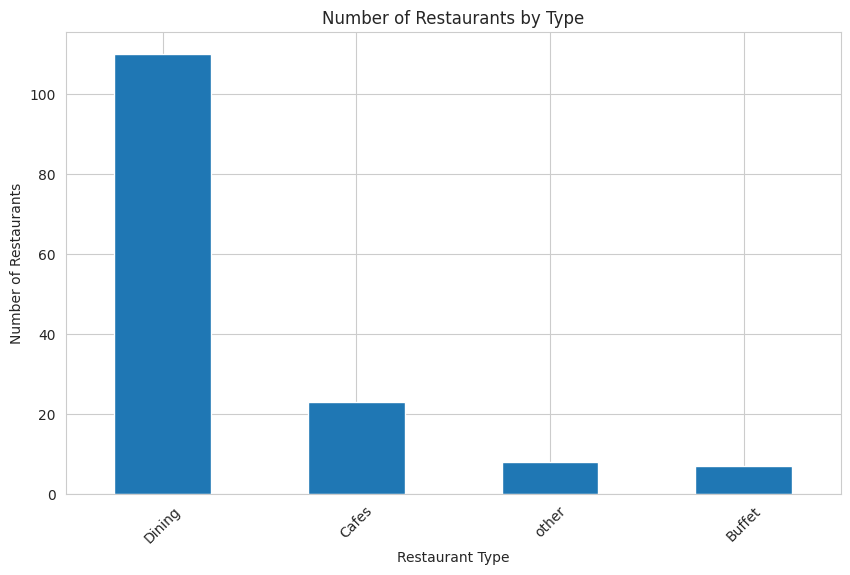

In [20]:
plt.figure(figsize=(10, 6))

restaurant_type_counts.plot(kind='bar')

plt.title('Number of Restaurants by Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=45)

plt.show()

In [21]:
most_popular_type = restaurant_type_counts.idxmax()
most_popular_count = restaurant_type_counts.max()

print("Most popular restaurant type:", most_popular_type)
print("Number of restaurants:", most_popular_count)

Most popular restaurant type: Dining
Number of restaurants: 110


In [22]:
votes_by_type = df.groupby('listed_in(type)')['votes'].sum().sort_values(ascending=False)

print(votes_by_type)

listed_in(type)
Dining    20363
other      9367
Cafes      6434
Buffet     3028
Name: votes, dtype: int64


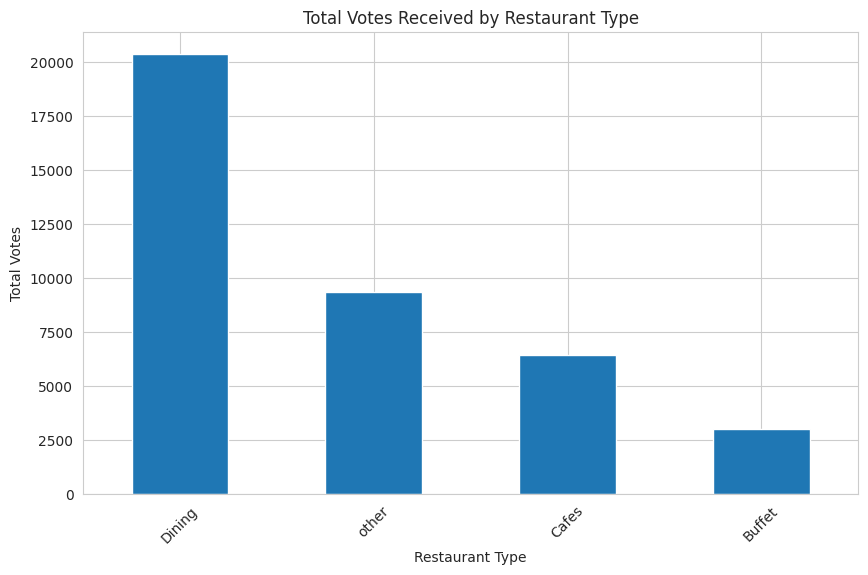

In [23]:
plt.figure(figsize=(10, 6))

votes_by_type.plot(kind='bar')

plt.title('Total Votes Received by Restaurant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Total Votes')

plt.xticks(rotation=45)

plt.show()

In [24]:
highest_vote_type = votes_by_type.idxmax()
highest_votes = votes_by_type.max()

print("Restaurant type with maximum votes:", highest_vote_type)
print("Total votes:", highest_votes)

Restaurant type with maximum votes: Dining
Total votes: 20363


In [25]:
rating_counts = df['rate'].value_counts().sort_index()

print(rating_counts)

rate
2.6     1
2.8     2
2.9     7
3.0     2
3.1     7
3.2     7
3.3    14
3.4    12
3.5     6
3.6    11
3.7    15
3.8    20
3.9    10
4.0    10
4.1    11
4.2     8
4.3     1
4.4     2
4.6     2
Name: count, dtype: int64


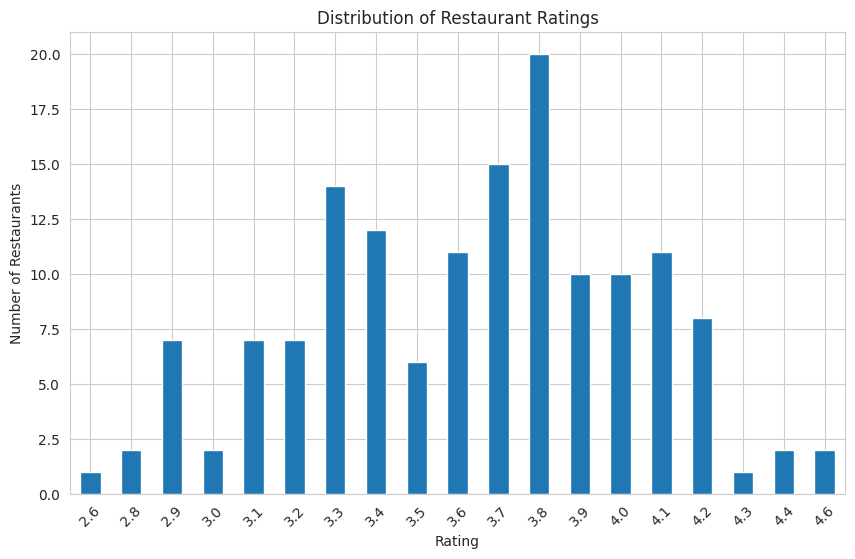

In [26]:
plt.figure(figsize=(10, 6))

rating_counts.plot(kind='bar')

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=45)

plt.show()

In [27]:
most_common_rating = df['rate'].mode()[0]

print("Most common restaurant rating:", most_common_rating)

Most common restaurant rating: 3.8


In [28]:
average_cost = df[cost_column].mean()

print("Average spending for two people:", round(average_cost, 2))

Average spending for two people: 418.24


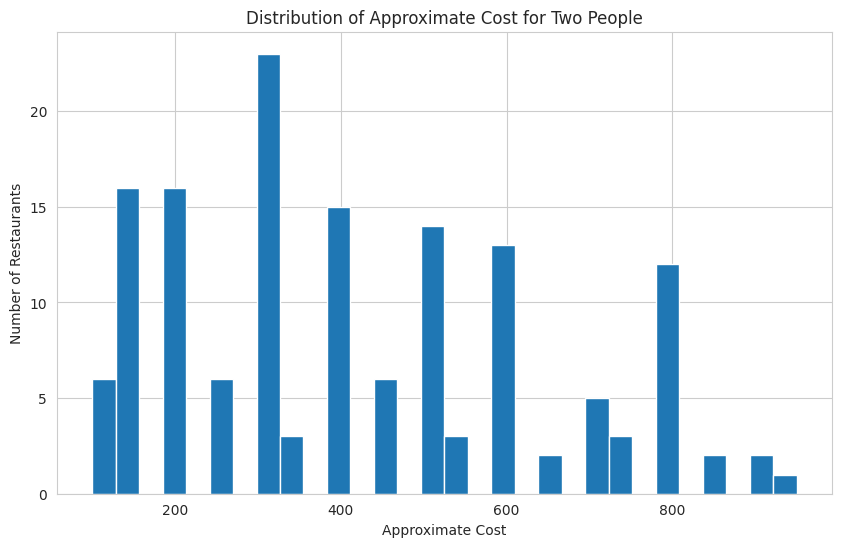

In [29]:
plt.figure(figsize=(10, 6))

plt.hist(df[cost_column].dropna(), bins=30)

plt.title('Distribution of Approximate Cost for Two People')
plt.xlabel('Approximate Cost')
plt.ylabel('Number of Restaurants')

plt.show()

In [30]:
average_rating_by_order = df.groupby('online_order')['rate'].mean()

print(average_rating_by_order)

online_order
No     3.487778
Yes    3.858621
Name: rate, dtype: float64


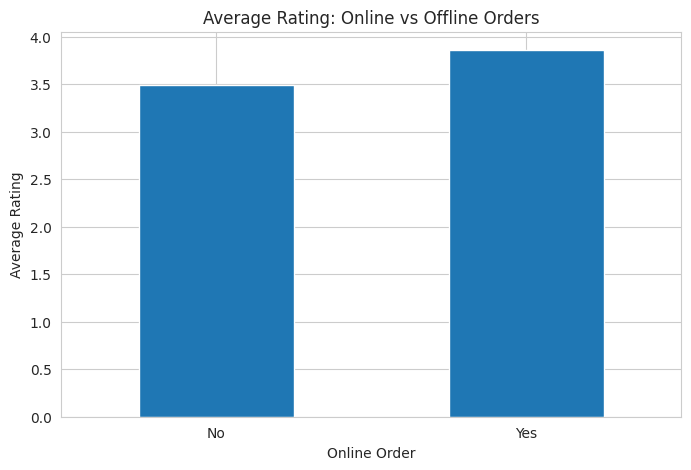

In [31]:
plt.figure(figsize=(8, 5))

average_rating_by_order.plot(kind='bar')

plt.title('Average Rating: Online vs Offline Orders')
plt.xlabel('Online Order')
plt.ylabel('Average Rating')

plt.xticks(rotation=0)

plt.show()

In [32]:
highest_rated_mode = average_rating_by_order.idxmax()
highest_rating = average_rating_by_order.max()

print("Mode with the highest average rating:", highest_rated_mode)
print("Average rating:", round(highest_rating, 2))

Mode with the highest average rating: Yes
Average rating: 3.86


In [33]:
offline_orders = df[df['online_order'] == 'No']

offline_by_type = offline_orders['listed_in(type)'].value_counts()

print(offline_by_type)

listed_in(type)
Dining    77
Cafes      8
Buffet     3
other      2
Name: count, dtype: int64


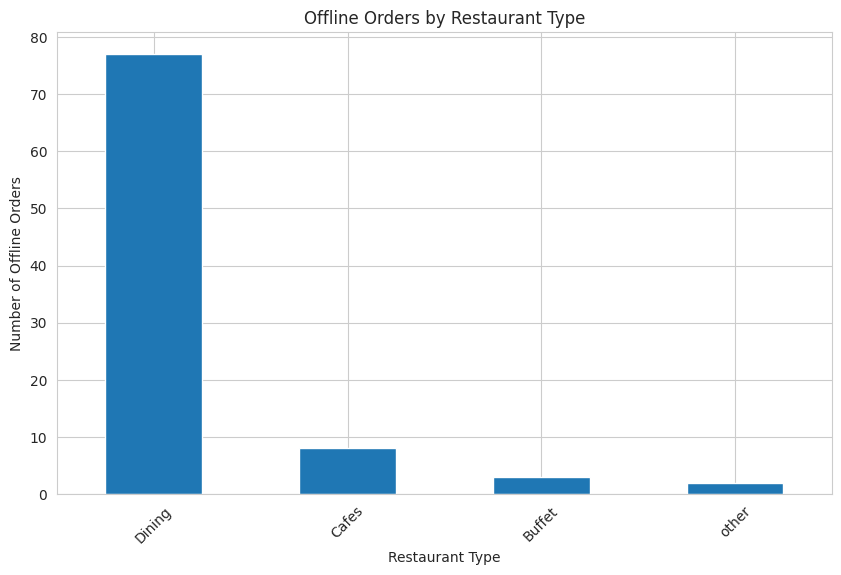

In [34]:
plt.figure(figsize=(10, 6))

offline_by_type.plot(kind='bar')

plt.title('Offline Orders by Restaurant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Offline Orders')

plt.xticks(rotation=45)

plt.show()

In [35]:
highest_offline_type = offline_by_type.idxmax()
highest_offline_orders = offline_by_type.max()

print("Restaurant type with maximum offline orders:", highest_offline_type)
print("Number of offline orders:", highest_offline_orders)

Restaurant type with maximum offline orders: Dining
Number of offline orders: 77


In [36]:
order_counts = df['online_order'].value_counts()

print(order_counts)

online_order
No     90
Yes    58
Name: count, dtype: int64


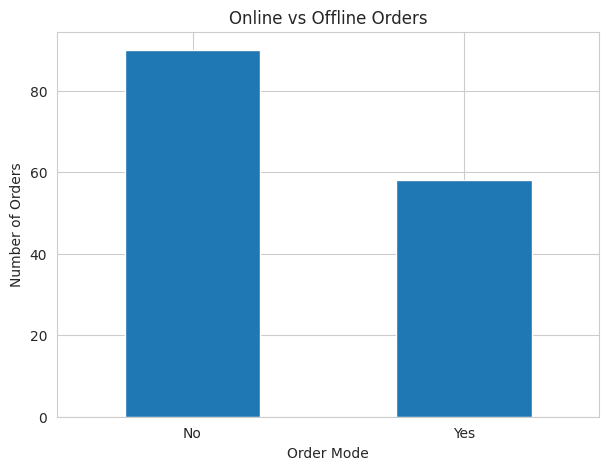

In [37]:
plt.figure(figsize=(7, 5))

order_counts.plot(kind='bar')

plt.title('Online vs Offline Orders')
plt.xlabel('Order Mode')
plt.ylabel('Number of Orders')

plt.xticks(rotation=0)

plt.show()

In [38]:
online_order_analysis = pd.crosstab(
    df['listed_in(type)'],
    df['online_order']
)

print(online_order_analysis)

online_order     No  Yes
listed_in(type)         
Buffet            3    4
Cafes             8   15
Dining           77   33
other             2    6


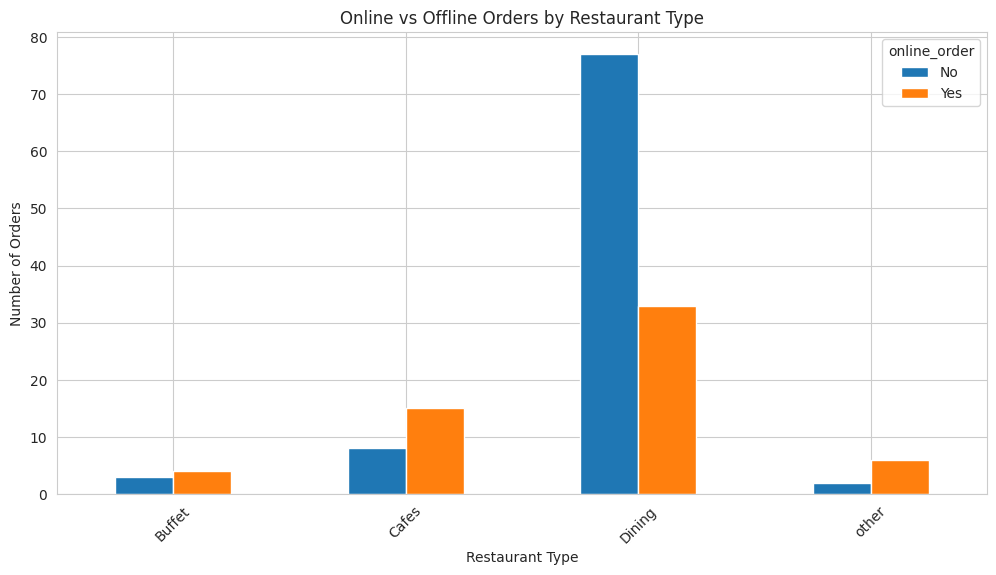

In [39]:
online_order_analysis.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Online vs Offline Orders by Restaurant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)

plt.show()

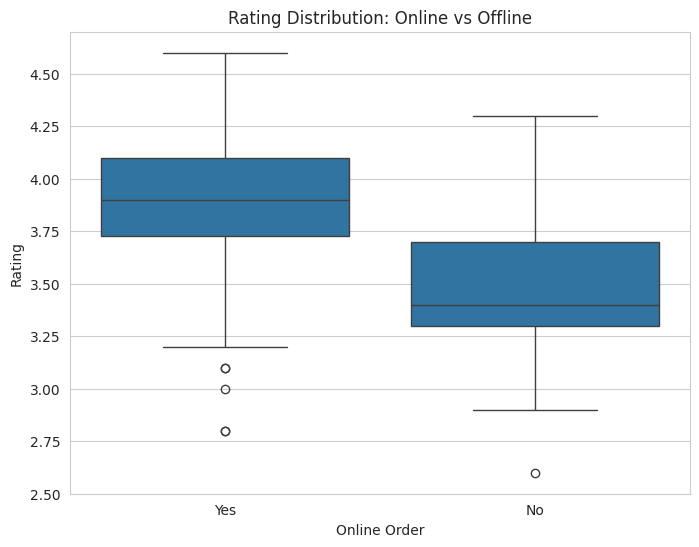

In [40]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='online_order',
    y='rate',
    data=df
)

plt.title('Rating Distribution: Online vs Offline')
plt.xlabel('Online Order')
plt.ylabel('Rating')

plt.show()

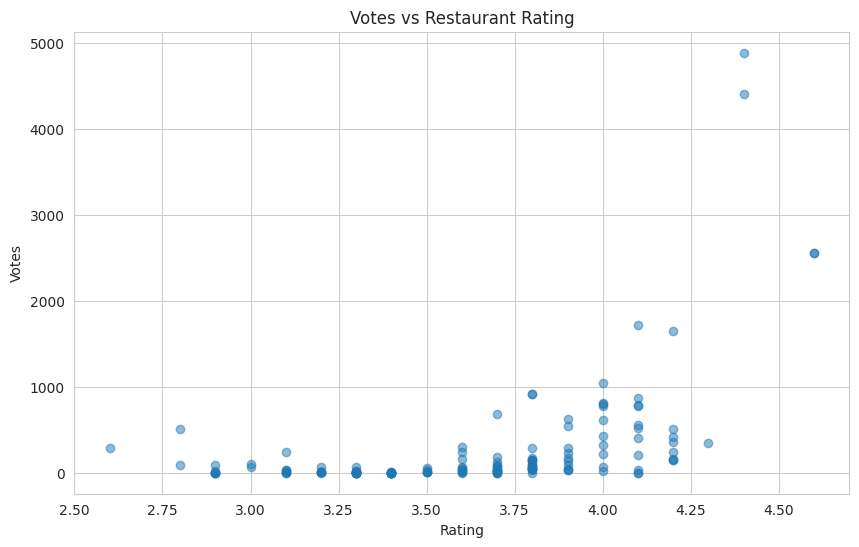

In [41]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['rate'],
    df['votes'],
    alpha=0.5
)

plt.title('Votes vs Restaurant Rating')
plt.xlabel('Rating')
plt.ylabel('Votes')

plt.show()

In [42]:
numeric_columns = df.select_dtypes(include=np.number)

correlation = numeric_columns.corr()

correlation

,rate,votes,approx_cost(for two people)
rate,1.000000,0.489844,0.275216
votes,0.489844,1.000000,0.324372
approx_cost(for two people),0.275216,0.324372,1.000000


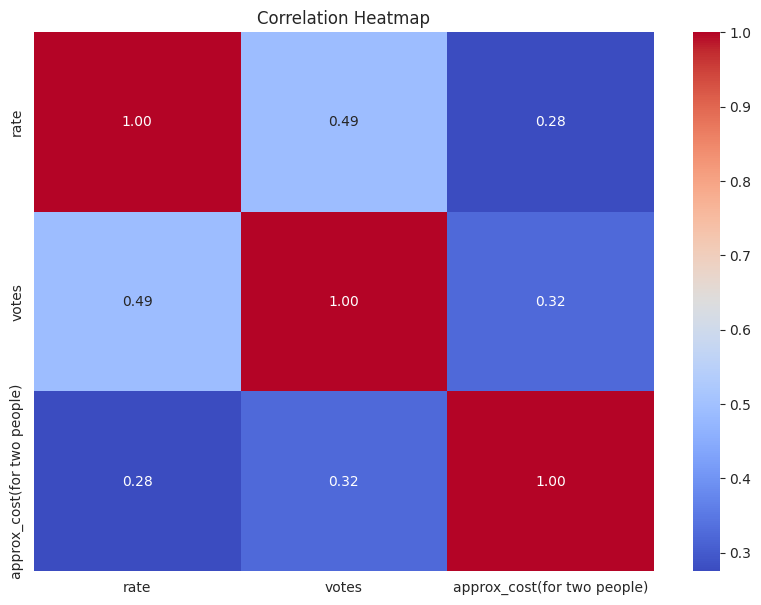

In [43]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [44]:
print("=" * 60)
print("ZOMATO DATA ANALYSIS - FINAL RESULTS")
print("=" * 60)

print("\n1. Most popular restaurant type:")
print(most_popular_type)

print("\n2. Restaurant type with maximum votes:")
print(highest_vote_type)
print("Total votes:", highest_votes)

print("\n3. Most common restaurant rating:")
print(most_common_rating)

print("\n4. Average spending for two people:")
print(round(average_cost, 2))

print("\n5. Mode with highest average rating:")
print(highest_rated_mode)
print("Average rating:", round(highest_rating, 2))

print("\n6. Restaurant type with maximum offline orders:")
print(highest_offline_type)
print("Offline orders:", highest_offline_orders)

print("\n" + "=" * 60)

ZOMATO DATA ANALYSIS - FINAL RESULTS

1. Most popular restaurant type:
Dining

2. Restaurant type with maximum votes:
Dining
Total votes: 20363

3. Most common restaurant rating:
3.8

4. Average spending for two people:
418.24

5. Mode with highest average rating:
Yes
Average rating: 3.86

6. Restaurant type with maximum offline orders:
Dining
Offline orders: 77

